# 阶段三 · 数据分析（3.1—3.5）

> 对应文档表 2 的步骤 **3.1 Benford 基线 → 3.2 Isolation Forest → 3.3 Top-K 召回 → 3.4 规则—模型交叉 → 3.5 人工归因**。

**输入：**

- `../data/audit_raw.csv`：原始金额、标签、业务字段（Benford 和案例归因要用原始尺度）；
- `../outputs/audit_clean.csv`：清洗后的特征矩阵；
- `../outputs/clean_feature_columns.csv`：111 个特征清单。

**本节要回答：**

1. 金额首位数字是否符合 Benford 分布？异常组是否偏离得更厉害？
2. Isolation Forest 能否把异常排在前面？Top-K 能命中多少？
3. Benford 规则和模型各自抓到什么？两者是互补还是重复？
4. 模型单独标记的可疑交易，从业务字段上能不能解释得通？

**重要原则：** 标签 `Abnormal_Label` 只用于**评估**，绝不参与模型训练或规则定义。Benford 标记也只根据金额分布本身推导。

## 0. 环境与数据

读取清洗后的特征矩阵，并核对它和原始数据的行顺序、标签完全一致。

In [1]:
import re
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 120)
pd.set_option('display.max_colwidth', 80)

BASE = Path('..')
RAW_PATH = BASE / 'data/audit_raw.csv'
CLEAN_PATH = BASE / 'outputs/audit_clean.csv'
FEATURE_PATH = BASE / 'outputs/clean_feature_columns.csv'
OUT_DIR = BASE / 'outputs'
FIG_DIR = OUT_DIR / 'figures'

RUN_TIME = datetime.now()
clean = pd.read_csv(CLEAN_PATH, encoding='utf-8-sig')
raw = pd.read_csv(RAW_PATH, encoding='utf-8')
feature_table = pd.read_csv(FEATURE_PATH, encoding='utf-8-sig')

features = feature_table['特征名'].tolist()
X = clean[features].to_numpy(dtype=float)
y = clean['Abnormal_Label'].to_numpy()

print('运行时间:', RUN_TIME.strftime('%Y-%m-%d %H:%M:%S'))
print(f'样本数: {len(clean):,} | 特征数: {len(features)} | 异常样本: {int(y.sum())} ({y.mean():.2%})')
print('特征矩阵:', X.shape, '| 有限值:', bool(np.isfinite(X).all()))

# 行顺序和标签必须与原始数据一致
assert clean['Transaction_ID'].equals(raw['Transaction_ID']), '行顺序不一致'
assert (clean['Abnormal_Label'] == raw['Abnormal_Label']).all(), '标签不一致'
print('行顺序与标签核对: 通过')

运行时间: 2026-10-18 23:09:25
样本数: 7,000 | 特征数: 111 | 异常样本: 955 (13.64%)
特征矩阵: (7000, 111) | 有限值: True
行顺序与标签核对: 通过


## 3.1 Benford 首位数字基线

**原理：** 在真实的财务数据中，金额的首位数字并不是均匀分布的，而是遵循 Benford 定律：

$$P(d) = \log_{10}\left(1 + \frac{1}{d}\right), \quad d = 1, 2, \dots, 9$$

首位是 1 的金额约占 30.1%，首位是 9 的只占 4.6%。如果数据被人为编造或拆分，首位数字分布往往会偏离这个规律。

**怎么做：**

1. 取每笔交易金额的首位数字（1–9）；
2. 统计实际频率，与 Benford 期望频率对比；
3. 计算 **MAD（平均绝对偏差）**：
   $$MAD = \frac{1}{9}\sum_{d=1}^{9} |P_{obs}(d) - P_{exp}(d)|$$

**MAD 判断标准（Nigrini）：**

| MAD | 判断 |
|---|---|
| < 0.006 | 高度符合 |
| 0.006 – 0.012 | 可接受 |
| 0.012 – 0.015 | 临界 |
| > 0.015 | 明显不符合 |

**注意：** Benford 是**分布层面**的检验。单笔交易的金额是否"异常"，不能只靠首位数字判断；它是发现整体数据造假的基线工具。

In [2]:
def first_digit(x):
    """取正数的首位数字；用科学计数法字符串避免浮点误差。"""
    x = abs(float(x))
    if not np.isfinite(x) or x == 0:
        return np.nan
    return int(f'{x:.10e}'[0])


raw['First_Digit'] = raw['Transaction_Amount_RMB'].map(first_digit)
assert raw['First_Digit'].notna().all(), '存在无法取首位数字的金额'

benford_expected = pd.Series(np.log10(1 + 1 / np.arange(1, 10)), index=range(1, 10))
digit_counts = raw['First_Digit'].value_counts().reindex(range(1, 10), fill_value=0)
observed = digit_counts / digit_counts.sum()

digit_table = pd.DataFrame({
    '首位数字': range(1, 10),
    '交易数': digit_counts.values,
    '实际占比': observed.round(4).values,
    "Benford 期望": benford_expected.round(4).values,
    '偏差(实际-期望)': (observed - benford_expected).round(4).values,
    '实际/期望': (observed / benford_expected).round(3).values,
})


def mad_level(mad):
    if mad < 0.006:
        return '高度符合'
    if mad < 0.012:
        return '可接受'
    if mad < 0.015:
        return '临界'
    return '明显不符合'


overall_mad = float((observed - benford_expected).abs().mean())
print('=== 总体首位数字分布 ===')
display(digit_table)
print(f'总体 MAD = {overall_mad:.5f} -> {mad_level(overall_mad)}')

# 按标签分组，看异常组是否偏离得更厉害（标签只用于评估）
label_rows = []
observed_by_label = {}
for lab, name in [(0, '正常'), (1, '异常')]:
    d = raw.loc[raw['Abnormal_Label'] == lab, 'First_Digit']
    counts = d.value_counts().reindex(range(1, 10), fill_value=0)
    obs = counts / counts.sum()
    observed_by_label[name] = obs
    mad = float((obs - benford_expected).abs().mean())
    label_rows.append({
        '组别': name,
        '样本数': len(d),
        'MAD': round(mad, 5),
        '判断': mad_level(mad),
    })

label_mad_table = pd.DataFrame(label_rows)
print('\n=== 分组 MAD ===')
display(label_mad_table)

by_label_table = pd.DataFrame({
    '首位数字': range(1, 10),
    '正常组实际占比': observed_by_label['正常'].round(4).values,
    '异常组实际占比': observed_by_label['异常'].round(4).values,
    'Benford 期望': benford_expected.round(4).values,
})
print('\n=== 分组首位数字分布 ===')
display(by_label_table)

digit_table.to_csv(OUT_DIR / 'benford_digit_table.csv', index=False, encoding='utf-8-sig')
by_label_table.to_csv(OUT_DIR / 'benford_by_label.csv', index=False, encoding='utf-8-sig')
label_mad_table.to_csv(OUT_DIR / 'benford_mad_by_label.csv', index=False, encoding='utf-8-sig')
print('\n已保存: benford_digit_table.csv / benford_by_label.csv / benford_mad_by_label.csv')

=== 总体首位数字分布 ===


,首位数字,交易数,实际占比,Benford 期望,偏差(实际-期望),实际/期望
0,1,2102,0.3003,0.3010,-0.0007,0.998
1,2,1236,0.1766,0.1761,0.0005,1.003
2,3,857,0.1224,0.1249,-0.0025,0.980
3,4,695,0.0993,0.0969,0.0024,1.025
4,5,662,0.0946,0.0792,0.0154,1.194
5,6,409,0.0584,0.0669,-0.0085,0.873
6,7,380,0.0543,0.0580,-0.0037,0.936
7,8,343,0.0490,0.0512,-0.0022,0.958
8,9,316,0.0451,0.0458,-0.0006,0.987


总体 MAD = 0.00405 -> 高度符合

=== 分组 MAD ===


,组别,样本数,MAD,判断
0,正常,6045,0.00325,高度符合
1,异常,955,0.03633,明显不符合



=== 分组首位数字分布 ===


,首位数字,正常组实际占比,异常组实际占比,Benford 期望
0,1,0.3064,0.2618,0.3010
1,2,0.1849,0.1236,0.1761
2,3,0.1252,0.1047,0.1249
3,4,0.0969,0.1141,0.0969
4,5,0.0787,0.1948,0.0792
5,6,0.0591,0.0545,0.0669
6,7,0.0572,0.0356,0.0580
7,8,0.0513,0.0346,0.0512
8,9,0.0402,0.0764,0.0458



已保存: benford_digit_table.csv / benford_by_label.csv / benford_mad_by_label.csv


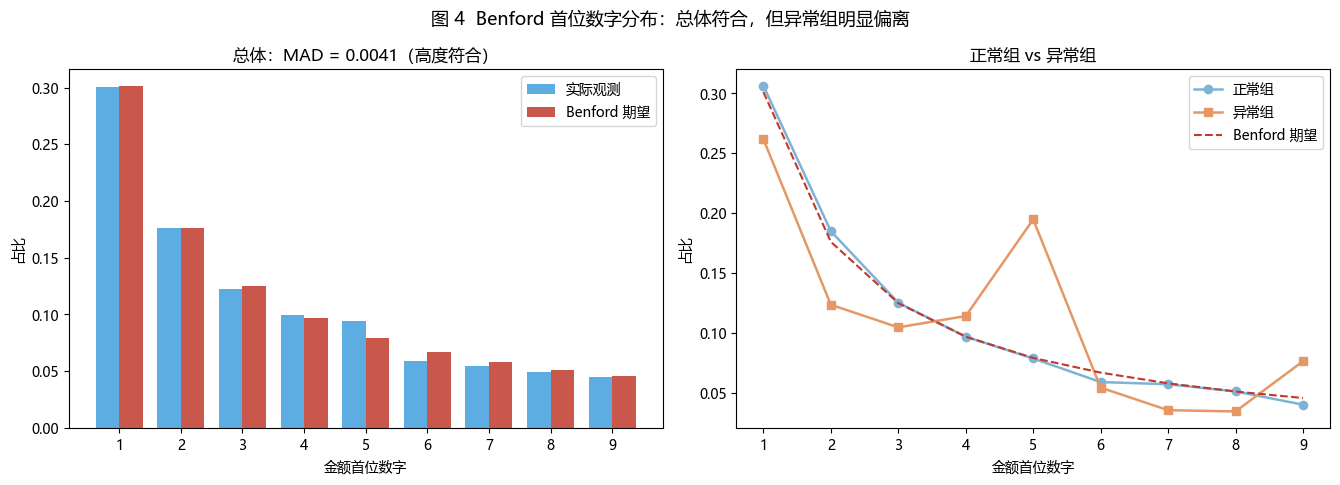

已保存: outputs/figures/04_benford_distribution.png


In [3]:
# 图 4：整体分布 + 正常/异常分组对比
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.9))
x = np.arange(1, 10)
width = 0.38

axes[0].bar(x - width / 2, observed.values, width, label='实际观测', color='#5DADE2')
axes[0].bar(x + width / 2, benford_expected.values, width, label='Benford 期望',
            color='#C0392B', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xlabel('金额首位数字')
axes[0].set_ylabel('占比')
axes[0].set_title(f'总体：MAD = {overall_mad:.4f}（{mad_level(overall_mad)}）')
axes[0].legend()

axes[1].plot(x, observed_by_label['正常'].values, marker='o', linewidth=1.8,
             label='正常组', color='#7FB3D5')
axes[1].plot(x, observed_by_label['异常'].values, marker='s', linewidth=1.8,
             label='异常组', color='#E59866')
axes[1].plot(x, benford_expected.values, linestyle='--', linewidth=1.5,
             label='Benford 期望', color='#C0392B')
axes[1].set_xticks(x)
axes[1].set_xlabel('金额首位数字')
axes[1].set_ylabel('占比')
axes[1].set_title('正常组 vs 异常组')
axes[1].legend()

fig.suptitle('图 4  Benford 首位数字分布：总体符合，但异常组明显偏离', fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / '04_benford_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('已保存: outputs/figures/04_benford_distribution.png')

**本数据集的结果：**

- **总体 MAD = 0.00405**，属于"高度符合"——单看整体，数据没有明显编造痕迹。
- 但分组后差异很大：
  - 正常组 MAD = **0.00325**（高度符合）；
  - 异常组 MAD = **0.03633**（明显不符合）。
- 偏差主要来自数字 **5**：总体实际占比 9.46%，期望 7.92%（比值 1.19）；在异常组中，数字 5 的占比高达 **19.48%**，数字 9 也偏高（7.64%）。
- 这说明：**整体符合 Benford 并不代表没有异常**。异常样本只占 13.64%，被正常样本稀释了；把异常组单独拎出来，才看得到明显的分布扭曲。
- 交易层面的简化规则：把"实际占比比期望高出 1 个百分点以上"的数字标为 Benford 可疑数字。本数据中只有 **数字 5** 满足（+1.54 个百分点），因此 `Benford_Flag = 1` 表示该笔金额首位为 5，共 **662 条（9.46%）**。

> 这是一个分布规律在单笔交易上的**粗粒度投影**，目的是和模型形成对照，不代表这 662 条都有问题。

## 3.2 Isolation Forest 异常打分

**原理：** Isolation Forest 用随机超平面不断切分数据。异常点通常"离群"，会被更少的切分隔离出来，因此平均路径长度更短。sklearn 的 `score_samples` 越大越正常，我们取负号，定义：

> **`anomaly_score = -score_samples`，分数越大越异常。**

**参数：**

- `n_estimators=200`：200 棵树，比默认 100 更稳定；
- `contamination=0.02`：按 2% 的比例设定判定阈值，即约 **140 条**被标为异常；
- `random_state=42`：保证结果可复现。

**注意：** `contamination` 不是"真实异常率"，而是我们愿意投入审计的容量。它决定阈值，不改变样本的分数排序。

In [4]:
CONTAMINATION = 0.02
N_ESTIMATORS = 200
RANDOM_STATE = 42

model = IsolationForest(
    n_estimators=N_ESTIMATORS,
    contamination=CONTAMINATION,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
model.fit(X)

# 取负号，让"分数越大 = 越异常"
scores = -model.score_samples(X)
pred = model.predict(X)                      # -1 表示异常
model_flag = (pred == -1).astype(int)

scores_df = pd.DataFrame({
    'Transaction_ID': clean['Transaction_ID'],
    'anomaly_score': scores,
    'model_flag': model_flag,
    'Abnormal_Label': clean['Abnormal_Label'],
    'Abnormal_Type': clean['Abnormal_Type'],
})

expected_flags = int(round(len(clean) * CONTAMINATION))
print(f'模型标记数: {int(model_flag.sum())}（contamination={CONTAMINATION}，预期 {expected_flags}）')
print(f'ROC-AUC: {roc_auc_score(y, scores):.4f}')
print(f'PR-AUC (Average Precision): {average_precision_score(y, scores):.4f}')
print(f'分数范围: {scores.min():.4f} ~ {scores.max():.4f}')

print('\n=== 异常分数最高的 10 条 ===')
display(scores_df.sort_values('anomaly_score', ascending=False).head(10))

scores_df.to_csv(OUT_DIR / 'isolation_forest_scores.csv', index=False, encoding='utf-8-sig')
print('\n已保存: outputs/isolation_forest_scores.csv')

模型标记数: 140（contamination=0.02，预期 140）
ROC-AUC: 0.8795
PR-AUC (Average Precision): 0.6466
分数范围: 0.4128 ~ 0.5099

=== 异常分数最高的 10 条 ===


,Transaction_ID,anomaly_score,model_flag,Abnormal_Label,Abnormal_Type
5219,CN-TXN-0005220,0.509892,1,1,Duplicate_Invoice
247,CN-TXN-0000248,0.505492,1,1,High_Risk_Vendor
397,CN-TXN-0000398,0.504979,1,1,Split_Transaction
99,CN-TXN-0000100,0.504807,1,1,Split_Transaction
5828,CN-TXN-0005829,0.504765,1,1,Duplicate_Invoice
664,CN-TXN-0000665,0.502449,1,1,Round_Trip_Transfer
6420,CN-TXN-0006421,0.499519,1,1,Round_Trip_Transfer
4862,CN-TXN-0004863,0.499476,1,1,Round_Trip_Transfer
6645,CN-TXN-0006646,0.498195,1,1,Split_Transaction
6024,CN-TXN-0006025,0.497985,1,1,Round_Trip_Transfer



已保存: outputs/isolation_forest_scores.csv


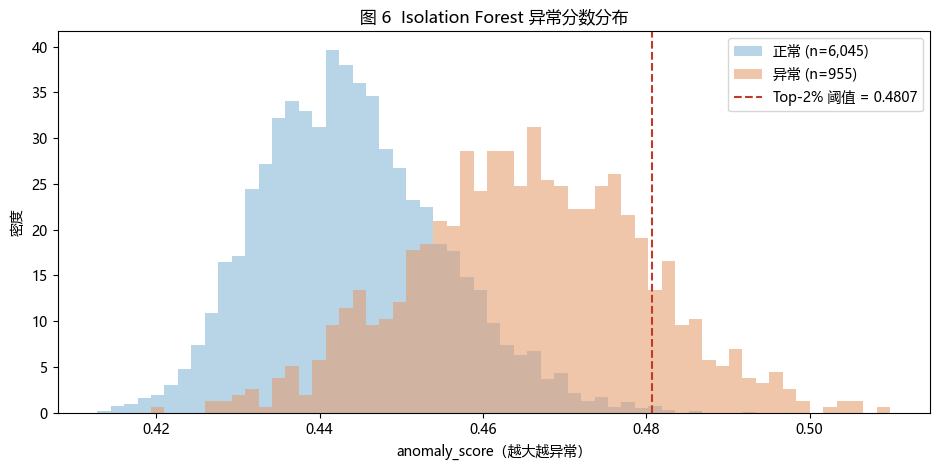

已保存: outputs/figures/06_anomaly_score_distribution.png


In [5]:
# 图 6：正常 vs 异常的分数分布
flag_threshold = float(np.quantile(scores, 1 - CONTAMINATION))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
bins = np.linspace(scores.min(), scores.max(), 60)
ax.hist(scores[y == 0], bins=bins, density=True, alpha=0.55,
        label=f'正常 (n={int((y == 0).sum()):,})', color='#7FB3D5')
ax.hist(scores[y == 1], bins=bins, density=True, alpha=0.55,
        label=f'异常 (n={int((y == 1).sum()):,})', color='#E59866')
ax.axvline(flag_threshold, color='#C0392B', linestyle='--', linewidth=1.5,
           label=f'Top-2% 阈值 = {flag_threshold:.4f}')
ax.set_xlabel('anomaly_score（越大越异常）')
ax.set_ylabel('密度')
ax.set_title('图 6  Isolation Forest 异常分数分布')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / '06_anomaly_score_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('已保存: outputs/figures/06_anomaly_score_distribution.png')

In [6]:
# 审计名单：按分数降序的前 140 条，附上关键业务字段，供人工复核
audit_cols = [
    'Transaction_ID', 'anomaly_score', 'Transaction_Amount_RMB',
    'Historical_Avg_Amount_RMB', 'Transaction_to_Avg_Ratio', 'Amount_Threshold_Ratio',
    'Approval_Delay_Min', 'Invoice_Match_Score', 'Vendor_Risk_Score',
    'Audit_Rule_Violation_Count', 'Relational_Anomaly_Score',
    'Abnormal_Label', 'Abnormal_Type',
]
merged_for_list = raw.merge(
    scores_df[['Transaction_ID', 'anomaly_score', 'model_flag']],
    on='Transaction_ID', how='left'
)
assert merged_for_list['anomaly_score'].notna().all()

top140_list = (merged_for_list[merged_for_list['model_flag'] == 1]
               .sort_values('anomaly_score', ascending=False)[audit_cols])
top140_list.to_csv(OUT_DIR / 'top140_audit_list.csv', index=False, encoding='utf-8-sig')

print(f'审计名单行数: {len(top140_list)}')
print('已保存: outputs/top140_audit_list.csv')
display(top140_list.head(8))

审计名单行数: 140
已保存: outputs/top140_audit_list.csv


,Transaction_ID,anomaly_score,Transaction_Amount_RMB,Historical_Avg_Amount_RMB,Transaction_to_Avg_Ratio,Amount_Threshold_Ratio,Approval_Delay_Min,Invoice_Match_Score,Vendor_Risk_Score,Audit_Rule_Violation_Count,Relational_Anomaly_Score,Abnormal_Label,Abnormal_Type
5219,CN-TXN-0005220,0.509892,14774.56,25215.21,0.5859,0.2955,338.55,0.4411,0.1471,4,0.4931,1,Duplicate_Invoice
247,CN-TXN-0000248,0.505492,40207.56,28741.73,1.3989,0.2010,90.43,0.6584,0.8591,4,0.5212,1,High_Risk_Vendor
397,CN-TXN-0000398,0.504979,487007.06,8554.90,56.9273,0.9740,91.52,0.9748,0.0973,2,0.3465,1,Split_Transaction
99,CN-TXN-0000100,0.504807,480173.97,11494.02,41.7760,0.9603,73.87,0.9858,0.0920,4,0.5105,1,Split_Transaction
5828,CN-TXN-0005829,0.504765,18053.23,15137.12,1.1926,0.0903,233.12,0.4397,0.7593,4,0.4818,1,Duplicate_Invoice
664,CN-TXN-0000665,0.502449,7523.63,7597.59,0.9903,0.0376,127.80,0.9071,0.6647,0,0.1987,1,Round_Trip_Transfer
6420,CN-TXN-0006421,0.499519,128749.37,43645.64,2.9499,2.5750,129.20,0.9354,0.3910,1,0.3607,1,Round_Trip_Transfer
4862,CN-TXN-0004863,0.499476,10262.08,12966.07,0.7915,0.0205,184.44,0.9294,0.0198,1,0.2279,1,Round_Trip_Transfer


**本数据集的结果：**

- 模型标记 **140 条**（正好是 2%）；
- **ROC-AUC = 0.8795**，**PR-AUC = 0.6466**——在有监督指标上表现不错（这两个指标只用于评估，模型训练没有用标签）；
- 分数最高的样本里，异常样本明显更集中；正常样本的分数集中在低分段；
- 完整分数和审计名单已保存：
  - `isolation_forest_scores.csv`：7,000 条全量分数；
  - `top140_audit_list.csv`：前 140 条 + 关键业务字段，可直接作为人工复核清单。

> 注意：`contamination=0.02` 只决定"切在哪"，分数排序本身不受影响。所以下一节的 Top-K 评估可以放心地取不同的 K。

## 3.3 Top-K 召回评估

**为什么不用准确率：** 异常只占 13.64%，全部猜"正常"也有 86.4% 的准确率。审计场景真正关心的是：

> 如果审计人员只能抽查 **K 条**，能抓到多少异常？

**指标：**

- **Precision@K（命中率）**：前 K 条里有多少条真的是异常 = 命中数 / K；
- **Recall@K（召回率）**：前 K 条覆盖了全部异常的多少 = 命中数 / 全部异常数（955）；
- **Lift（提升倍数）**：Precision@K ÷ 异常占比 13.64%，表示比随机抽查好多少倍。

文档要求取 K = 50 / 100 / 140，这里额外画出完整的 K–召回曲线，方便根据审计人力选择 K。

In [7]:
order = np.argsort(-scores)          # 按异常分数降序的索引
total_pos = int(y.sum())

ks = [10, 20, 30, 40, 50, 75, 100, 125, 140, 160, 200,
      250, 300, 400, 500, 750, 1000, 1500, 2000]
rows = []
for k in ks:
    top = order[:k]
    hits = int(y[top].sum())
    rows.append({
        'K': k,
        '命中数': hits,
        'Precision@K': hits / k,
        'Recall@K': hits / total_pos,
        'Lift': (hits / k) / y.mean(),
    })

topk_table = pd.DataFrame(rows)
print('=== Top-K 指标 ===')
display(topk_table.round(4))

print('\n=== 文档要求的 K = 50 / 100 / 140 ===')
display(topk_table[topk_table['K'].isin([50, 100, 140])].round(4))

topk_table.to_csv(OUT_DIR / 'topk_metrics.csv', index=False, encoding='utf-8-sig')
print('已保存: outputs/topk_metrics.csv')

=== Top-K 指标 ===


,K,命中数,Precision@K,Recall@K,Lift
0,10,10,1.0000,0.0105,7.3298
1,20,20,1.0000,0.0209,7.3298
2,30,29,0.9667,0.0304,7.0855
3,40,39,0.9750,0.0408,7.1466
4,50,49,0.9800,0.0513,7.1832
5,75,72,0.9600,0.0754,7.0366
6,100,96,0.9600,0.1005,7.0366
7,125,119,0.9520,0.1246,6.9780
8,140,129,0.9214,0.1351,6.7539
9,160,144,0.9000,0.1508,6.5969



=== 文档要求的 K = 50 / 100 / 140 ===


,K,命中数,Precision@K,Recall@K,Lift
4,50,49,0.9800,0.0513,7.1832
6,100,96,0.9600,0.1005,7.0366
8,140,129,0.9214,0.1351,6.7539


已保存: outputs/topk_metrics.csv


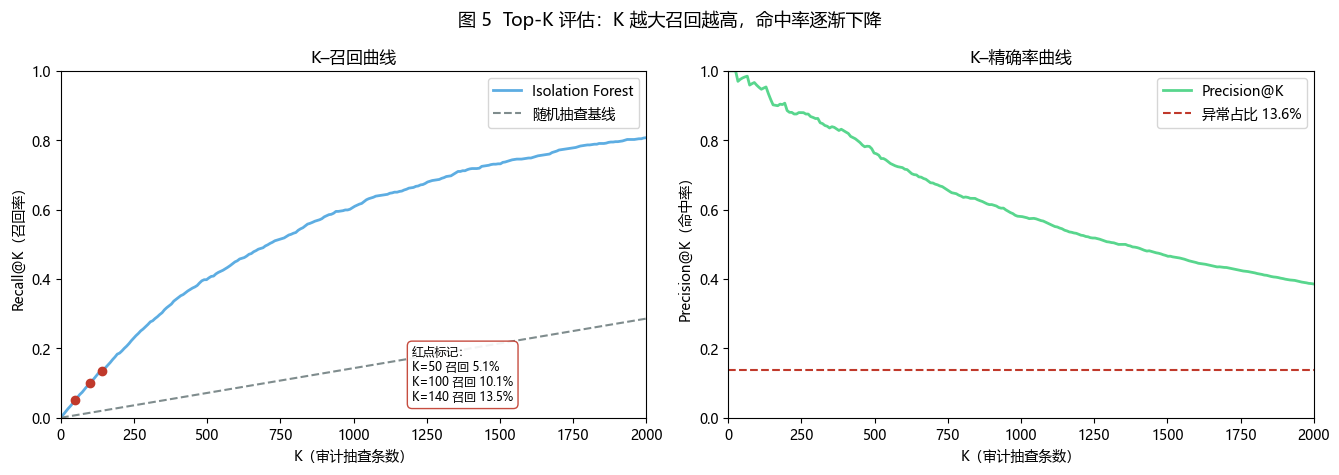

已保存: outputs/figures/05_topk_recall.png


In [8]:
# 图 5：K–召回曲线 + K–精确率曲线
k_grid = np.unique(np.linspace(1, 2000, 250).astype(int))
recall_curve = np.array([y[order[:k]].sum() / total_pos for k in k_grid])
precision_curve = np.array([y[order[:k]].sum() / k for k in k_grid])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

axes[0].plot(k_grid, recall_curve, color='#5DADE2', linewidth=2, label='Isolation Forest')
axes[0].plot(k_grid, k_grid / len(y), linestyle='--', color='#7F8C8D', label='随机抽查基线')
for k in [50, 100, 140]:
    r = y[order[:k]].sum() / total_pos
    axes[0].scatter([k], [r], color='#C0392B', zorder=5)
summary_lines = ['红点标记：'] + [
    f"K={k} 召回 {y[order[:k]].sum() / total_pos:.1%}" for k in (50, 100, 140)
]
axes[0].text(0.60, 0.04, '\n'.join(summary_lines), transform=axes[0].transAxes,
             fontsize=8.5, va='bottom', ha='left',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                       edgecolor='#C0392B', alpha=0.9))
axes[0].set_xlabel('K（审计抽查条数）')
axes[0].set_ylabel('Recall@K（召回率）')
axes[0].set_title('K–召回曲线')
axes[0].set_xlim(0, 2000)
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].plot(k_grid, precision_curve, color='#58D68D', linewidth=2, label='Precision@K')
axes[1].axhline(y.mean(), linestyle='--', color='#C0392B', label=f'异常占比 {y.mean():.1%}')
axes[1].set_xlabel('K（审计抽查条数）')
axes[1].set_ylabel('Precision@K（命中率）')
axes[1].set_title('K–精确率曲线')
axes[1].set_xlim(0, 2000)
axes[1].set_ylim(0, 1)
axes[1].legend()

fig.suptitle('图 5  Top-K 评估：K 越大召回越高，命中率逐渐下降', fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / '05_topk_recall.png', dpi=150, bbox_inches='tight')
plt.show()
print('已保存: outputs/figures/05_topk_recall.png')

**本数据集的结果：**

| K | 命中数 | Precision@K | Recall@K | Lift |
|---:|---:|---:|---:|---:|
| 50 | 49 | 98.0% | 5.1% | 7.18× |
| 100 | 96 | 96.0% | 10.1% | 7.04× |
| 140 | 129 | 92.1% | 13.5% | 6.75× |
| 300 | 259 | 86.3% | 27.1% | 6.33× |
| 500 | 380 | 76.0% | 39.8% | 5.57× |
| 1000 | 578 | 57.8% | 60.5% | 4.24× |

**怎么读：**

- 资源有限、只抽查 50 条时，前 50 条里有 **49 条**是异常，命中率 98%，但只覆盖全部异常的 5.1%；
- 抽查 140 条时，命中率仍有 **92.1%**，覆盖 13.5%；
- 如果审计能力能到 500 条，可以覆盖约 **40%** 的异常；到 1000 条，覆盖约 **60.5%**；
- 随机抽查 140 条的期望命中率只有 13.64%，模型提升了约 **6.75 倍**。

> 这就是"Top-K 召回"的实用含义：**先保证审计名单的质量（命中率），再根据人力决定查多少（召回率）**。

## 3.4 Benford 规则 × 模型 Top-140 交叉

**Benford 标记的定义（不使用标签）：**

- 在 3.1 中，实际占比比 Benford 期望高出 1 个百分点以上的数字被标为"可疑数字"；
- 本数据只有数字 **5** 满足条件；
- 因此 `Benford_Flag = 1` 表示金额首位数字是 5，共 662 条。

**模型标记的定义：** `contamination=0.02` 对应的前 140 条（按 `anomaly_score` 降序）。

**为什么要交叉：**

- 规则（Benford）和模型（Isolation Forest）看问题的角度不同；
- 如果两者高度重叠，说明模型只是复述规则；
- 如果两者互补，说明可以组合成"规则初筛 + 模型排序"的流程。

In [9]:
# 规则阈值：实际占比 - 期望占比 > 1 个百分点
BENFORD_DEVIATION_THRESHOLD = 0.01
benford_flag_digits = digit_table.loc[
    digit_table['偏差(实际-期望)'] > BENFORD_DEVIATION_THRESHOLD, '首位数字'
].tolist()
print('被标为可疑的首位数字:', benford_flag_digits)

raw['Benford_Flag'] = raw['First_Digit'].isin(benford_flag_digits).astype(int)
print(f'Benford 标记数: {int(raw["Benford_Flag"].sum())} ({raw["Benford_Flag"].mean():.2%})')

# 合并规则标记和模型分数
analysis = raw[['Transaction_ID', 'First_Digit', 'Benford_Flag',
                'Abnormal_Label', 'Abnormal_Type']].merge(
    scores_df[['Transaction_ID', 'anomaly_score', 'model_flag']],
    on='Transaction_ID', how='left'
)
assert analysis['anomaly_score'].notna().all(), '合并后存在缺失分数'

# 模型 Top-140 与 predict 的 -1 集合对比（阈值并列时可能有极少数差异）
top140_flag = np.zeros(len(scores), dtype=int)
top140_flag[order[:140]] = 1
analysis['model_top140'] = top140_flag
same_set = bool((analysis['model_top140'] == analysis['model_flag']).all())
print(f'Top-140 与 predict(-1) 集合完全一致: {same_set}')
if not same_set:
    print('提示：阈值附近存在并列，后续统一使用按分数排序的 Top-140')

count_table = pd.crosstab(
    analysis['Benford_Flag'], analysis['model_top140'],
    margins=True, rownames=['Benford 标记'], colnames=['模型 Top-140']
)
print('\n=== 2×2 交叉（条数）===')
display(count_table)

cell_stats = (analysis.groupby(['Benford_Flag', 'model_top140'])['Abnormal_Label']
              .agg(记录数='count', 异常数='sum', 异常率='mean')
              .reset_index())
print('\n=== 每个格子的异常率 ===')
display(cell_stats.round(4))

rate_pivot = cell_stats.pivot(index='Benford_Flag', columns='model_top140', values='异常率')
print('\n=== 异常率矩阵 ===')
display(rate_pivot.round(4))

overlap = int(((analysis['Benford_Flag'] == 1) & (analysis['model_top140'] == 1)).sum())
union = int(((analysis['Benford_Flag'] == 1) | (analysis['model_top140'] == 1)).sum())
print(f'\n重叠条数: {overlap} | 并集条数: {union} | Jaccard 相似度: {overlap / union:.4f}')

count_table.to_csv(OUT_DIR / 'model_benford_crosstab.csv', encoding='utf-8-sig')
cell_stats.to_csv(OUT_DIR / 'model_benford_cell_stats.csv', index=False, encoding='utf-8-sig')
analysis.to_csv(OUT_DIR / 'rule_model_flags.csv', index=False, encoding='utf-8-sig')
print('已保存: model_benford_crosstab.csv / model_benford_cell_stats.csv / rule_model_flags.csv')

被标为可疑的首位数字: [5]
Benford 标记数: 662 (9.46%)
Top-140 与 predict(-1) 集合完全一致: True

=== 2×2 交叉（条数）===


模型 Top-140,0,1,All
Benford 标记,,,
0,6216,122,6338
1,644,18,662
All,6860,140,7000



=== 每个格子的异常率 ===


,Benford_Flag,model_top140,记录数,异常数,异常率
0,0,0,6216,657,0.1057
1,0,1,122,112,0.9180
2,1,0,644,169,0.2624
3,1,1,18,17,0.9444



=== 异常率矩阵 ===


model_top140,0,1
Benford_Flag,,
0,0.1057,0.9180
1,0.2624,0.9444



重叠条数: 18 | 并集条数: 784 | Jaccard 相似度: 0.0230
已保存: model_benford_crosstab.csv / model_benford_cell_stats.csv / rule_model_flags.csv


**本数据集的结果：**

| | 模型未标记 | 模型 Top-140 | 合计 |
|---|---:|---:|---:|
| **Benford 未标记** | 6,216（异常率 10.6%） | 122（异常率 **91.8%**） | 6,338 |
| **Benford 标记** | 644（异常率 **26.2%**） | 18（异常率 **94.4%**） | 662 |
| **合计** | 6,860 | 140 | 7,000 |

**怎么读：**

- **模型单独标记（Benford=0, 模型=1）**：122 条，异常率 **91.8%**。这是模型的强项——它能抓到 Benford 规则看不出来的多字段组合异常。
- **Benford 单独标记（Benford=1, 模型=0）**：644 条，异常率 **26.2%**，约为基准 13.64% 的 **1.9 倍**。规则有信号，但精度低、范围宽，适合做初筛。
- **两者同时标记**：只有 **18 条**，但异常率 **94.4%**，是纯度最高的格子。
- **两者都不标记**：6,216 条，异常率 10.6%，明显低于基准。
- **Jaccard 相似度约 0.023**，说明两者重合度很低——**不是互相复述，而是互补**。

**结论：** 如果只用 Benford，会捞出大量低价值线索；如果只用模型，会漏掉规则型的分布异常。合理的流程是：

1. 用 Benford 做全量初筛（宽口径）；
2. 用模型分数排序，优先审计高风险样本；
3. 对"两者同时命中"的 18 条优先核查，对"仅模型命中"的 122 条做重点归因。

## 3.5 人工归因：从"仅模型标记"中挑 3 条

**为什么挑"仅模型标记"：** 这一格最能体现模型的价值——规则没发现，但模型认为异常。人工阅读金额、审批、发票、供应商、关系网络等字段，检查模型的判断在业务上是否说得通。

**选样规则：** 从 `Benford_Flag=0` 且 `model_flag=1` 的 122 条中，按 `anomaly_score` 降序取前 3 条。

**注意：** 这里的归因是"字段层面的解释"，不等于审计定性；真实审计还需要凭证、合同、银行流水等外部证据。

另外要区分清楚：`Abnormal_Type` 是数据自带的**真实标签**，只用于事后对照和命名案例；**模型本身只输出异常分数，不预测异常类型**。所以下面说"这是 Duplicate_Invoice 案例"，意思是"它的真实类型是重复发票"，不是"模型判断它是重复发票"。

In [10]:
merged = raw.merge(
    scores_df[['Transaction_ID', 'anomaly_score', 'model_flag']],
    on='Transaction_ID', how='left'
)
assert merged['anomaly_score'].notna().all()

model_only = (merged[(merged['model_flag'] == 1) & (merged['Benford_Flag'] == 0)]
              .sort_values('anomaly_score', ascending=False))

case_cols = [
    'Transaction_ID', 'anomaly_score', 'Abnormal_Label', 'Abnormal_Type',
    'Transaction_Amount_RMB', 'Historical_Avg_Amount_RMB', 'Transaction_to_Avg_Ratio',
    'Approval_Threshold_RMB', 'Amount_Threshold_Ratio',
    'Approval_Delay_Min', 'Invoice_Match_Score', 'Vendor_Risk_Score',
    'Audit_Rule_Violation_Count', 'Relational_Anomaly_Score',
]
cases = model_only.head(3)[case_cols].copy()


def explain_case(row):
    """根据实际字段值生成一句归因说明，避免手写结论和数据脱节。"""
    reasons = []
    if row['Approval_Delay_Min'] > 120:
        reasons.append(f"审批延迟 {row['Approval_Delay_Min']:.0f} 分钟（全样本均值约 72 分钟）")
    if row['Invoice_Match_Score'] < 0.6:
        reasons.append(f"发票匹配分仅 {row['Invoice_Match_Score']:.2f}（全样本均值约 0.90）")
    if row['Vendor_Risk_Score'] > 0.6:
        reasons.append(f"供应商风险分 {row['Vendor_Risk_Score']:.2f}（全样本均值约 0.30）")
    if row['Transaction_to_Avg_Ratio'] > 10:
        reasons.append(f"金额是历史均值的 {row['Transaction_to_Avg_Ratio']:.1f} 倍")
    if row['Amount_Threshold_Ratio'] > 0.9:
        reasons.append(f"金额达到审批阈值的 {row['Amount_Threshold_Ratio']:.1%}，紧贴阈值")
    if row['Audit_Rule_Violation_Count'] >= 3:
        reasons.append(f"触发 {int(row['Audit_Rule_Violation_Count'])} 条审计规则")
    if row['Relational_Anomaly_Score'] > 0.45:
        reasons.append(f"关系异常分 {row['Relational_Anomaly_Score']:.2f}（全样本均值约 0.27）")
    if not reasons:
        reasons.append('单项字段不突出，异常来自多维组合')
    return '；'.join(reasons)


cases['归因说明'] = cases.apply(explain_case, axis=1)

print('=== 3 条人工归因案例 ===')
display(cases[['Transaction_ID', 'Abnormal_Type', 'anomaly_score',
               'Transaction_Amount_RMB', 'Transaction_to_Avg_Ratio',
               'Approval_Delay_Min', 'Invoice_Match_Score', 'Vendor_Risk_Score',
               'Audit_Rule_Violation_Count', '归因说明']])

print('\n=== 逐条说明 ===')
for _, row in cases.iterrows():
    print(f"\n{row['Transaction_ID']}（真实类型：{row['Abnormal_Type']}，仅用于对照）")
    print(f"  异常分数: {row['anomaly_score']:.4f}")
    print(f"  归因: {row['归因说明']}")

cases.to_csv(OUT_DIR / 'case_studies.csv', index=False, encoding='utf-8-sig')
print('\n已保存: outputs/case_studies.csv')

=== 3 条人工归因案例 ===


,Transaction_ID,Abnormal_Type,anomaly_score,Transaction_Amount_RMB,Transaction_to_Avg_Ratio,Approval_Delay_Min,Invoice_Match_Score,Vendor_Risk_Score,Audit_Rule_Violation_Count,归因说明
5219,CN-TXN-0005220,Duplicate_Invoice,0.509892,14774.56,0.5859,338.55,0.4411,0.1471,4,审批延迟 339 分钟（全样本均值约 72 分钟）；发票匹配分仅 0.44（全样本均值约 0.90）；触发 4 条审计规则；关系异常分 0.49（全样本...
247,CN-TXN-0000248,High_Risk_Vendor,0.505492,40207.56,1.3989,90.43,0.6584,0.8591,4,供应商风险分 0.86（全样本均值约 0.30）；触发 4 条审计规则；关系异常分 0.52（全样本均值约 0.27）
397,CN-TXN-0000398,Split_Transaction,0.504979,487007.06,56.9273,91.52,0.9748,0.0973,2,金额是历史均值的 56.9 倍；金额达到审批阈值的 97.4%，紧贴阈值



=== 逐条说明 ===

CN-TXN-0005220（真实类型：Duplicate_Invoice，仅用于对照）
  异常分数: 0.5099
  归因: 审批延迟 339 分钟（全样本均值约 72 分钟）；发票匹配分仅 0.44（全样本均值约 0.90）；触发 4 条审计规则；关系异常分 0.49（全样本均值约 0.27）

CN-TXN-0000248（真实类型：High_Risk_Vendor，仅用于对照）
  异常分数: 0.5055
  归因: 供应商风险分 0.86（全样本均值约 0.30）；触发 4 条审计规则；关系异常分 0.52（全样本均值约 0.27）

CN-TXN-0000398（真实类型：Split_Transaction，仅用于对照）
  异常分数: 0.5050
  归因: 金额是历史均值的 56.9 倍；金额达到审批阈值的 97.4%，紧贴阈值

已保存: outputs/case_studies.csv


**三条案例的解读：**

1. **CN-TXN-0005220（真实类型：Duplicate_Invoice，重复发票）**
   - 审批延迟 **338.55 分钟**，约为全样本均值 71.96 分钟的 **4.7 倍**；
   - 发票匹配分 **0.44**，远低于均值 0.90；
   - 触发 **4 条**审计规则，关系异常分 0.49（均值 0.27）。
   - **解释：** 金额本身并不夸张（1.48 万，仅为历史均值的 0.59 倍），异常主要来自"审批异常拖沓 + 发票匹配差 + 多项规则违反"的组合。这正是 Benford 规则看不到、模型能捕捉的类型。

2. **CN-TXN-0000248（真实类型：High_Risk_Vendor，高风险供应商）**
   - 供应商风险分 **0.86**，约为均值 0.30 的 **2.9 倍**；
   - 触发 **4 条**审计规则；
   - 金额 4.02 万，是历史均值的 1.40 倍，审批延迟 90 分钟（略高于均值）。
   - **解释：** 单看金额不算离谱，但交易对手本身风险很高，模型把它排到前列是合理的。审计应优先核查该供应商的合同与资质。

3. **CN-TXN-0000398（真实类型：Split_Transaction，拆分交易）**
   - 金额 **487,007 元**，是历史均值 8,555 元的 **56.9 倍**；
   - 金额达到审批阈值的 **97.4%**（阈值约 50 万），刻意压在阈值以下；
   - 触发 2 条审计规则；发票匹配分 0.97、供应商风险分 0.10，这两项看起来正常。
   - **解释：** 这是典型的"拆分交易"信号——金额极大且紧贴审批阈值，目的是规避更高层级的审批。只看发票和供应商字段会漏掉它，必须结合金额与阈值的关系。

**三条案例的共同点：** 它们分别对应"审批/发票异常""交易对手风险""金额规避阈值"三种模式，说明模型不是只依赖某一个字段，而是在多维特征上综合打分。

### 附：模型 Top-140 的真实类型构成

模型本身不预测类型，下面只是用真实标签 `Abnormal_Type` 做**事后统计**，看看它到底抓到了哪些类型的异常。

这一步能回答两个问题：

1. 模型是只盯着某一种异常，还是能覆盖多种模式？
2. 140 条里有多少条其实是正常样本（假阳性）？

In [11]:
type_totals = raw['Abnormal_Type'].value_counts()

# 用全部类型做 reindex，保证 Cross_Province_Mismatch 这类"一条都没进 Top-140"的类型也显示出来
top140_types = (merged[merged['model_flag'] == 1]['Abnormal_Type']
                .value_counts()
                .reindex(type_totals.index, fill_value=0)
                .rename_axis('真实异常类型')
                .reset_index(name='条数'))
top140_types['该类总数'] = top140_types['真实异常类型'].map(type_totals)
top140_types['占Top140'] = top140_types['条数'] / 140
top140_types['该类入选率'] = top140_types['条数'] / top140_types['该类总数']
top140_types = top140_types.sort_values('条数', ascending=False).reset_index(drop=True)

print('=== Top-140 的真实类型构成（事后统计）===')
display(top140_types.round(4))

normal_count = int(top140_types.loc[top140_types['真实异常类型'] == 'Normal', '条数'].sum())
print(f'其中真实标签为 Normal 的条数: {normal_count}（假阳性，占 Top-140 的 {normal_count / 140:.1%}）')
covered_types = top140_types[(top140_types['真实异常类型'] != 'Normal') &
                             (top140_types['条数'] > 0)]
print(f'覆盖的异常类型数: {len(covered_types)}')
print('未进入 Top-140 的类型:',
      top140_types.loc[(top140_types['条数'] == 0) &
                       (top140_types['真实异常类型'] != 'Normal'), '真实异常类型'].tolist())

top140_types.to_csv(OUT_DIR / 'top140_type_composition.csv', index=False, encoding='utf-8-sig')
print('已保存: outputs/top140_type_composition.csv')

=== Top-140 的真实类型构成（事后统计）===


,真实异常类型,条数,该类总数,占Top140,该类入选率
0,Round_Trip_Transfer,42,107,0.3000,0.3925
1,Duplicate_Invoice,28,109,0.2000,0.2569
2,Unusual_Amount_Spike,17,175,0.1214,0.0971
3,Split_Transaction,15,142,0.1071,0.1056
4,Normal,11,6045,0.0786,0.0018
5,High_Risk_Vendor,11,141,0.0786,0.0780
6,Tax_ID_Mismatch,11,74,0.0786,0.1486
7,Temporal_Burst,5,92,0.0357,0.0543
8,Cross_Province_Mismatch,0,115,0.0000,0.0000


其中真实标签为 Normal 的条数: 11（假阳性，占 Top-140 的 7.9%）
覆盖的异常类型数: 7
未进入 Top-140 的类型: ['Cross_Province_Mismatch']
已保存: outputs/top140_type_composition.csv


**本数据集的结果：**

| 真实类型 | 条数 | 占 Top-140 | 该类入选率 |
|---|---:|---:|---:|
| Round_Trip_Transfer（资金回流） | 42 | 30.0% | **39.3%** |
| Duplicate_Invoice（重复发票） | 28 | 20.0% | **25.7%** |
| Unusual_Amount_Spike（金额突增） | 17 | 12.1% | 9.7% |
| Split_Transaction（拆分交易） | 15 | 10.7% | 10.6% |
| Normal（正常，假阳性） | 11 | 7.9% | 0.18% |
| High_Risk_Vendor（高风险供应商） | 11 | 7.9% | 7.8% |
| Tax_ID_Mismatch（税号不符） | 11 | 7.9% | 14.9% |
| Temporal_Burst（时间聚集） | 5 | 3.6% | 5.4% |
| Cross_Province_Mismatch（跨省不匹配） | 0 | 0.0% | **0.0%** |

> 该类入选率 = 该类被模型选入 Top-140 的条数 ÷ 该类总数。对 `Normal` 行，它是假阳性率（11 / 6,045 = 0.18%），不是召回率。

- 140 条覆盖了 **7 种异常类型**；`Cross_Province_Mismatch` 共 115 条，**一条都没进 Top-140**——这是模型明确的短板；
- 假阳性 **11 条（7.9%）**，与前面 92.1% 的精确率一致；
- 资金回流（39.3%）和重复发票（25.7%）的入选率最高，说明模型对这两类模式最敏感；
- 这个构成比"模型准确率 92%"更能说明模型"抓到了什么、漏掉了什么"，可以直接放进汇报。

## 分析小结

| 任务 | 结果 | 留痕 |
|---|---|---|
| Benford 总体 | MAD = 0.00405，高度符合 | `benford_digit_table.csv` |
| Benford 分组 | 正常 0.00325；异常 **0.03633**（明显不符合） | `benford_by_label.csv`、`benford_mad_by_label.csv` |
| 可疑数字 | 数字 5（高出期望 1.54 个百分点），标记 662 条 | `rule_model_flags.csv` |
| Isolation Forest | 标记 140 条；ROC-AUC 0.8795；PR-AUC 0.6466 | `isolation_forest_scores.csv` |
| Top-50 | 命中 49 条，Precision 98.0%，Recall 5.1% | `topk_metrics.csv` |
| Top-140 | 命中 129 条，Precision 92.1%，Recall 13.5% | `top140_audit_list.csv` |
| 规则 × 模型 | 仅模型 122 条（异常率 91.8%）；两者同时 18 条（94.4%） | `model_benford_crosstab.csv` |
| 人工归因 | 3 条案例，覆盖三种异常模式 | `case_studies.csv` |
| 类型构成 | 覆盖 7 类；资金回流入选率 39.3%；假阳性 11 条（7.9%）；跨省不匹配 0 | `top140_type_composition.csv` |

**生成的文件：**

| 文件 | 内容 |
|---|---|
| `benford_digit_table.csv` | 1–9 首位数字的实际/期望占比、偏差、MAD |
| `benford_by_label.csv` | 正常组 vs 异常组的首位数字分布 |
| `benford_mad_by_label.csv` | 分组 MAD 与判断 |
| `isolation_forest_scores.csv` | 7,000 条异常分数、模型标记、标签 |
| `top140_audit_list.csv` | 前 140 条审计名单 + 关键业务字段 |
| `topk_metrics.csv` | 各 K 的命中数、精确率、召回率、Lift |
| `model_benford_crosstab.csv` | 规则 × 模型 2×2 计数表 |
| `model_benford_cell_stats.csv` | 2×2 每格的记录数、异常数、异常率 |
| `rule_model_flags.csv` | 每条记录的 Benford 标记、模型分数与标记 |
| `case_studies.csv` | 3 条人工归因案例 |
| `top140_type_composition.csv` | Top-140 的真实类型构成（事后统计） |
| `figures/04_benford_distribution.png` | Benford 分布图 |
| `figures/05_topk_recall.png` | K–召回 / K–精确率曲线 |
| `figures/06_anomaly_score_distribution.png` | 异常分数分布图 |

**下一阶段（文档 4.1—4.3 汇报）：**

1. 从已有图表中选 5—6 张统一配色和字号；
2. 按 10 页结构制作 PPT：定位 → 学了什么 → 为何选审计 → 获取 → 清洗 2 页 → 分析 2 页 → 理解修正 → 收束；
3. 准备答辩问答：为什么不用有监督、`contamination` 怎么定、缺失为什么没删、Benford 和模型为何互补。

In [12]:
# 保存文字版分析日志
log_lines = [
    '智慧审计数据集 · 分析日志',
    f'生成时间: {RUN_TIME:%Y-%m-%d %H:%M:%S}',
    f'输入特征: {FEATURE_PATH.resolve()}（{len(features)} 列）',
    f'样本数: {len(clean)} | 异常样本: {int(y.sum())} ({y.mean():.2%})',
    '',
    '3.1 Benford:',
    f'  总体 MAD = {overall_mad:.5f}（{mad_level(overall_mad)}）',
]
for _, row in label_mad_table.iterrows():
    log_lines.append(f"  {row['组别']}组 MAD = {row['MAD']:.5f}（{row['判断']}），n={row['样本数']}")
for d in benford_flag_digits:
    dev = float(digit_table.loc[digit_table['首位数字'] == d, '偏差(实际-期望)'].iloc[0])
    log_lines.append(f'  可疑数字 {d}: 偏差 {dev:+.4f}')
log_lines.append(f'  Benford 标记数: {int(raw["Benford_Flag"].sum())}')

log_lines += [
    '',
    '3.2 Isolation Forest:',
    f'  n_estimators={N_ESTIMATORS}, contamination={CONTAMINATION}, random_state={RANDOM_STATE}',
    f'  标记数: {int(model_flag.sum())}',
    f'  ROC-AUC = {roc_auc_score(y, scores):.4f}',
    f'  PR-AUC  = {average_precision_score(y, scores):.4f}',
    '',
    '3.3 Top-K:',
]
for _, row in topk_table[topk_table['K'].isin([50, 100, 140, 300, 500, 1000])].iterrows():
    log_lines.append(
        f"  K={int(row['K'])}: 命中 {int(row['命中数'])}, "
        f"precision={row['Precision@K']:.4f}, recall={row['Recall@K']:.4f}, lift={row['Lift']:.2f}"
    )

log_lines += ['', '3.3 Top-140 类型构成（事后统计）:']
for _, row in top140_types.iterrows():
    log_lines.append(
        f"  {row['真实异常类型']}: {int(row['条数'])}/{int(row['该类总数'])}"
        f"（入选率 {row['该类入选率']:.1%}）"
    )

log_lines += [
    '',
    '3.4 规则-模型交叉:',
    f'  重叠 {overlap} 条, 并集 {union} 条, Jaccard={overlap / union:.4f}',
]
for _, row in cell_stats.iterrows():
    log_lines.append(
        f"  Benford={int(row['Benford_Flag'])}, model_top140={int(row['model_top140'])}: "
        f"记录 {int(row['记录数'])}, 异常 {int(row['异常数'])}, 异常率 {row['异常率']:.4f}"
    )

log_lines += [
    '',
    '3.5 人工归因:',
]
for _, row in cases.iterrows():
    log_lines.append(f"  {row['Transaction_ID']} [{row['Abnormal_Type']}]: {row['归因说明']}")

log_lines += [
    '',
    '说明: 标签仅用于评估，未参与训练或规则定义。',
]
(OUT_DIR / 'analysis_log.txt').write_text('\n'.join(log_lines), encoding='utf-8')
print('已保存: outputs/analysis_log.txt\n')
print('\n'.join(log_lines))

已保存: outputs/analysis_log.txt

智慧审计数据集 · 分析日志
生成时间: 2026-10-18 23:09:25
输入特征: D:\ProjectFiles\VscodeProject\audit_ml_project\outputs\clean_feature_columns.csv（111 列）
样本数: 7000 | 异常样本: 955 (13.64%)

3.1 Benford:
  总体 MAD = 0.00405（高度符合）
  正常组 MAD = 0.00325（高度符合），n=6045
  异常组 MAD = 0.03633（明显不符合），n=955
  可疑数字 5: 偏差 +0.0154
  Benford 标记数: 662

3.2 Isolation Forest:
  n_estimators=200, contamination=0.02, random_state=42
  标记数: 140
  ROC-AUC = 0.8795
  PR-AUC  = 0.6466

3.3 Top-K:
  K=50: 命中 49, precision=0.9800, recall=0.0513, lift=7.18
  K=100: 命中 96, precision=0.9600, recall=0.1005, lift=7.04
  K=140: 命中 129, precision=0.9214, recall=0.1351, lift=6.75
  K=300: 命中 259, precision=0.8633, recall=0.2712, lift=6.33
  K=500: 命中 380, precision=0.7600, recall=0.3979, lift=5.57
  K=1000: 命中 578, precision=0.5780, recall=0.6052, lift=4.24

3.3 Top-140 类型构成（事后统计）:
  Round_Trip_Transfer: 42/107（入选率 39.3%）
  Duplicate_Invoice: 28/109（入选率 25.7%）
  Unusual_Amount_Spike: 17/175（入选率 9.7%）
  Split_Transa